# Milestone 9B — Radial Profiles & λR Methodology Audit
**Target:** MaNGA 8138-12704 · HYB10-MILESHC-MASTARSSP

This supplementary notebook closes the remaining Milestone 9 checks:
- Inspect the velocity and corrected-dispersion radial profiles.
- Compare λR weighting schemes using the DAP bin geometry and flux definitions.
- Save figures and a concise audit report.

It does not assume that any one λR weighting is automatically correct. It exposes the alternatives and records the inputs so the final adopted method can be justified.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

PROJECT_ROOT = Path(r"D:\KS\manga-stellar-kinematics")
MAPS_PATH = PROJECT_ROOT / "data" / "raw" / "manga-8138-12704-MAPS-HYB10-MILESHC-MASTARSSP.fits.gz"
REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

maps = fits.open(MAPS_PATH, memmap=True)

ImportError: numpy._core.multiarray failed to import

## 1. Load the validated stellar-bin quantities

The DAP data model defines `BIN_MFLUX` as the g-band-weighted mean flux for the binned spectra, and `BIN_AREA` as the area of each bin. `BIN_LWELLCOO` provides the light-weighted elliptical coordinates, including R/Re and azimuth. We use these native bin-level products rather than treating a spaxel count as the physical area without checking.

In [ ]:
binid = np.asarray(maps["BINID"].data[1])
vel_map = np.asarray(maps["STELLAR_VEL"].data, float)
vel_ivar_map = np.asarray(maps["STELLAR_VEL_IVAR"].data, float)
vel_mask_map = np.asarray(maps["STELLAR_VEL_MASK"].data, np.uint32)
sig_raw_map = np.asarray(maps["STELLAR_SIGMA"].data, float)
sig_ivar_map = np.asarray(maps["STELLAR_SIGMA_IVAR"].data, float)
sig_mask_map = np.asarray(maps["STELLAR_SIGMA_MASK"].data, np.uint32)
sigcorr_map = np.asarray(maps["STELLAR_SIGMACORR"].data[0], float)

bin_mflux_map = np.asarray(maps["BIN_MFLUX"].data, float)
bin_area_map = np.asarray(maps["BIN_AREA"].data, float)
bin_farea_map = np.asarray(maps["BIN_FAREA"].data, float)
bin_lwell = np.asarray(maps["BIN_LWELLCOO"].data, float)

ids = np.unique(binid[binid >= 0])
records = []
for bid in ids:
    yy, xx = np.where(binid == bid)
    # DAP maps carry one fitted value across all spaxels in a stellar bin.
    y0, x0 = yy[0], xx[0]
    sig2 = sig_raw_map[y0, x0]**2 - sigcorr_map[y0, x0]**2
    sigc = np.sqrt(sig2) if np.isfinite(sig2) and sig2 >= 0 else np.nan
    records.append({
        "binid": int(bid), "n_spaxels": len(yy),
        "vel": vel_map[y0, x0], "vel_ivar": vel_ivar_map[y0, x0],
        "vel_mask": int(vel_mask_map[y0, x0]),
        "sigma_raw": sig_raw_map[y0, x0], "sigma_corr": sigc,
        "sigma_ivar": sig_ivar_map[y0, x0],
        "sigma_mask": int(sig_mask_map[y0, x0]),
        "R_Re": bin_lwell[1, y0, x0],
        "R_arcsec": bin_lwell[0, y0, x0],
        "theta_deg": bin_lwell[3, y0, x0],
        "bin_mflux": bin_mflux_map[y0, x0],
        "bin_area_arcsec2": bin_area_map[y0, x0],
        "bin_farea": bin_farea_map[y0, x0]
    })
df = pd.DataFrame(records)
print(df.describe(include="all").T)

                   count         mean         std         min         25%  \
binid             2194.0  1096.500000  633.497566    0.000000  548.250000   
n_spaxels         2194.0     1.232452    1.522809    1.000000    1.000000   
vel               2194.0    29.726834  139.354431 -207.714386  -96.947405   
vel_ivar          2194.0     0.065301    0.085283    0.004509    0.028599   
vel_mask          2194.0     0.000000    0.000000    0.000000    0.000000   
sigma_raw         2194.0   106.663690   25.821402   53.873310   89.326506   
sigma_corr        2194.0   104.868847   26.009453   51.077433   87.470596   
sigma_ivar        2194.0     0.047933    0.078564    0.002989    0.016896   
sigma_mask        2194.0     0.000000    0.000000    0.000000    0.000000   
R_Re              2194.0     0.986905    0.360865    0.001636    0.730307   
R_arcsec          2194.0    10.723119    3.920947    0.017779    7.935078   
theta_deg         2194.0   180.478230  104.403003    0.076447   88.995293   

## 2. Apply quality selection and inspect bin geometry

The stellar footprint is defined by non-negative stellar BINID. DAP mask bits are applied to the representative bin measurement. We then compare the pixel-count estimate of bin area with the native `BIN_AREA` extension. This is a diagnostic; the DAP native area is preferred for physical-area weighting.

In [ ]:
EXCLUDED_BITS = sum(1 << b for b in [0,1,2,3,4,5,6,7,8,9,30])
df["valid"] = (
    ((df["vel_mask"].astype(np.uint64) & EXCLUDED_BITS) == 0) &
    ((df["sigma_mask"].astype(np.uint64) & EXCLUDED_BITS) == 0) &
    np.isfinite(df["vel"]) & np.isfinite(df["sigma_corr"]) &
    np.isfinite(df["vel_ivar"]) & (df["vel_ivar"] > 0) &
    np.isfinite(df["sigma_ivar"]) & (df["sigma_ivar"] > 0) &
    np.isfinite(df["R_Re"]) & (df["R_Re"] >= 0) &
    np.isfinite(df["bin_mflux"]) & (df["bin_mflux"] > 0) &
    np.isfinite(df["bin_area_arcsec2"]) & (df["bin_area_arcsec2"] > 0)
)
d = df.loc[df.valid].copy()
d["v_resid"] = d["vel"] - np.nanmedian(d["vel"])
print("Valid stellar bins:", len(d))
print("Total covered spaxels:", int(df.n_spaxels.sum()))
print("Singleton bins:", int((df.n_spaxels == 1).sum()))
print("Median BIN_AREA [arcsec^2]:", d.bin_area_arcsec2.median())
print("Median spaxel-count area:", d.n_spaxels.median())
print("BIN_AREA / n_spaxels median:", (d.bin_area_arcsec2 / d.n_spaxels).median())
display(d[["n_spaxels","bin_area_arcsec2","bin_farea"]].describe())

Valid stellar bins: 2194
Total covered spaxels: 2704
Singleton bins: 2072
Median BIN_AREA [arcsec^2]: 0.25
Median spaxel-count area: 1.0
BIN_AREA / n_spaxels median: 0.25


,n_spaxels,bin_area_arcsec2,bin_farea
count,2194.000000,2194.000000,2194.0
mean,1.232452,0.308113,1.0
std,1.522809,0.380702,0.0
min,1.000000,0.250000,1.0
25%,1.000000,0.250000,1.0
50%,1.000000,0.250000,1.0
75%,1.000000,0.250000,1.0
max,29.000000,7.250000,1.0


## 3. Radial velocity and dispersion profiles

Profiles are computed in 0.5 Re annuli using the light-weighted bin radius. Both the median and the number of bins are shown. These are descriptive profiles, not deprojected rotation curves.

,R_Re_center,R_Re_low,R_Re_high,n_bins,median_v_resid_km_s,median_sigma_km_s,median_sigma_raw_km_s
0,0.25,0.0,0.5,254,-10.184611,156.685437,158.131020
1,0.75,0.5,1.0,770,-5.709579,110.516430,112.285679
2,1.25,1.0,1.5,1076,5.223139,89.479257,91.333241
3,1.75,1.5,2.0,94,22.935036,91.672539,93.544933


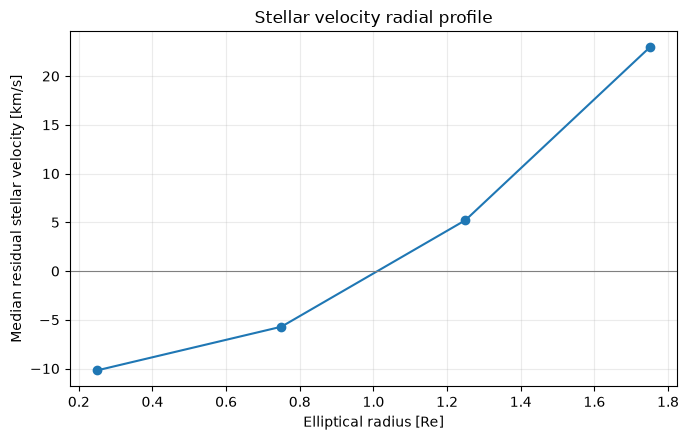

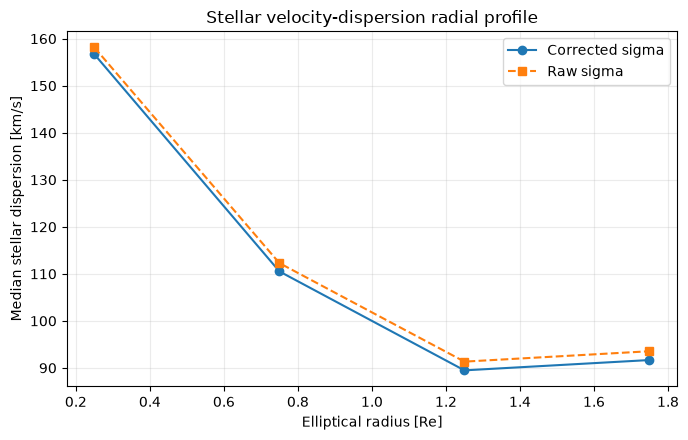

In [ ]:
edges = np.arange(0, np.nanmax(d.R_Re) + 0.5001, 0.5)
if len(edges) < 3:
    edges = np.linspace(0, np.nanmax(d.R_Re) + 1e-6, 4)
centers = 0.5 * (edges[:-1] + edges[1:])
rows = []
for lo, hi, cen in zip(edges[:-1], edges[1:], centers):
    q = d[(d.R_Re >= lo) & (d.R_Re < hi)]
    rows.append({
        "R_Re_center": cen, "R_Re_low": lo, "R_Re_high": hi,
        "n_bins": len(q),
        "median_v_resid_km_s": q.v_resid.median() if len(q) else np.nan,
        "median_sigma_km_s": q.sigma_corr.median() if len(q) else np.nan,
        "median_sigma_raw_km_s": q.sigma_raw.median() if len(q) else np.nan
    })
profile = pd.DataFrame(rows)
display(profile)

fig, ax = plt.subplots(figsize=(7,4.5))
ax.plot(profile.R_Re_center, profile.median_v_resid_km_s, "o-")
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xlabel="Elliptical radius [Re]", ylabel="Median residual stellar velocity [km/s]",
       title="Stellar velocity radial profile")
ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(FIG_DIR / "milestone9_velocity_radial_profile.png")
plt.show()

fig, ax = plt.subplots(figsize=(7,4.5))
ax.plot(profile.R_Re_center, profile.median_sigma_km_s, "o-", label="Corrected sigma")
ax.plot(profile.R_Re_center, profile.median_sigma_raw_km_s, "s--", label="Raw sigma")
ax.set(xlabel="Elliptical radius [Re]", ylabel="Median stellar dispersion [km/s]",
       title="Stellar velocity-dispersion radial profile")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
fig.savefig(FIG_DIR / "milestone9_dispersion_radial_profile.png")
plt.show()

## 4. λR weighting audit

The commonly used projected λR estimator is a luminosity-weighted sum over spatial elements:
λR = Σ(Fᵢ Rᵢ |Vᵢ|) / Σ(Fᵢ Rᵢ √(Vᵢ² + σᵢ²)).

For binned spectra, the total contribution of a bin depends on the bin's integrated light, not merely the number of bin IDs. The MAPS data model describes `BIN_MFLUX` as a mean flux per spaxel and `BIN_AREA` as bin area. We therefore compare:
- `BIN_MFLUX` alone (per-bin proxy; not automatically the integrated-bin luminosity),
- `BIN_MFLUX × BIN_AREA` (area-integrated proxy),
- `BIN_MFLUX × n_spaxels` (spaxel-count proxy).

These are diagnostic alternatives. The adopted estimator must be justified by the exact flux and area definitions and any fractional-bin edge treatment. This notebook does not silently select a preferred value.

In [ ]:
def calc_lambda(frame, weight_col, aperture):
    q = frame[
        (frame.R_Re <= aperture) &
        np.isfinite(frame[weight_col]) & (frame[weight_col] > 0) &
        np.isfinite(frame.v_resid) & np.isfinite(frame.sigma_corr)
    ]
    F = q[weight_col].to_numpy()
    R = q.R_Re.to_numpy()
    V = np.abs(q.v_resid.to_numpy())
    S = q.sigma_corr.to_numpy()
    den = np.sum(F * R * np.sqrt(V**2 + S**2))
    num = np.sum(F * R * V)
    return num / den if den > 0 else np.nan, len(q)

d["weight_per_bin"] = d.bin_mflux
d["weight_area"] = d.bin_mflux * d.bin_area_arcsec2
d["weight_spaxel_count"] = d.bin_mflux * d.n_spaxels
lambda_rows = []
for aperture in [1.0, 2.0]:
    for label, col in [
        ("BIN_MFLUX_per_bin", "weight_per_bin"),
        ("BIN_MFLUX_times_BIN_AREA", "weight_area"),
        ("BIN_MFLUX_times_n_spaxels", "weight_spaxel_count")
    ]:
        val, n = calc_lambda(d, col, aperture)
        lambda_rows.append({"aperture_Re": aperture, "weighting": label, "lambda_R": val, "n_bins": n})
lambda_table = pd.DataFrame(lambda_rows)
display(lambda_table)
lambda_table.to_csv(REPORT_DIR / "milestone9_lambdaR_methodology_audit.csv", index=False)

,aperture_Re,weighting,lambda_R,n_bins
0,1.0,BIN_MFLUX_per_bin,0.646215,1024
1,1.0,BIN_MFLUX_times_BIN_AREA,0.646215,1024
2,1.0,BIN_MFLUX_times_n_spaxels,0.646215,1024
3,2.0,BIN_MFLUX_per_bin,0.715598,2194
4,2.0,BIN_MFLUX_times_BIN_AREA,0.699775,2194
5,2.0,BIN_MFLUX_times_n_spaxels,0.699775,2194


## 5. Save the Milestone 9B audit outputs

Upload the generated CSV and report, plus the two radial-profile PNG figures. These outputs are required before declaring Milestone 9 fully complete.

In [ ]:
report = [
    "Milestone 9B — Radial Profiles and lambda_R Methodology Audit",
    f"Valid stellar bins: {len(d)}",
    f"Covered spaxels represented: {int(df.n_spaxels.sum())}",
    f"Singleton bins: {int((df.n_spaxels == 1).sum())}",
    "",
    "Radial profiles:",
    profile.to_string(index=False),
    "",
    "Lambda_R methodology comparison:",
    lambda_table.to_string(index=False),
    "",
    "Caution: all values are projected quantities. BIN_MFLUX weighting alternatives are diagnostics;",
    "final adoption requires justification of bin flux, bin area, fractional area and spatial sampling."
]
report_path = REPORT_DIR / "milestone9_radial_lambdaR_audit.txt"
report_path.write_text("\n".join(report), encoding="utf-8")
profile.to_csv(REPORT_DIR / "milestone9_radial_profiles.csv", index=False)
print(report_path)
print(report_path.read_text(encoding="utf-8"))
maps.close()

D:\KS\manga-stellar-kinematics\outputs\reports\milestone9_radial_lambdaR_audit.txt
Milestone 9B — Radial Profiles and lambda_R Methodology Audit
Valid stellar bins: 2194
Covered spaxels represented: 2704
Singleton bins: 2072

Radial profiles:
 R_Re_center  R_Re_low  R_Re_high  n_bins  median_v_resid_km_s  median_sigma_km_s  median_sigma_raw_km_s
        0.25       0.0        0.5     254           -10.184611         156.685437             158.131020
        0.75       0.5        1.0     770            -5.709579         110.516430             112.285679
        1.25       1.0        1.5    1076             5.223139          89.479257              91.333241
        1.75       1.5        2.0      94            22.935036          91.672539              93.544933

Lambda_R methodology comparison:
 aperture_Re                 weighting  lambda_R  n_bins
         1.0         BIN_MFLUX_per_bin  0.646215    1024
         1.0  BIN_MFLUX_times_BIN_AREA  0.646215    1024
         1.0 BIN_MFLUX_time